<a href="https://colab.research.google.com/github/Atharv-Vyahalkar/Yuva-Intern--Junior-Machine-Learning-Data-Analyst---Agriculture-Agribusiness/blob/main/Agriculture_Data_Analysis_Week_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [50]:
Df = pd.read_csv("Crop Data 24-25.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [51]:
print("Shape of the dataset (rows and columns):")
print(Df.shape)

Shape of the dataset (rows and columns):
(25239, 7)


In [52]:
print("First Five rows of the Dataset:")
print(Df.head())
print("\nLast Five rows of the Dataset:")
print(Df.tail())

First Five rows of the Dataset:
                         State  District               Crop  Season  \
0  Andaman And Nicobar Islands  Nicobars               Rice  Kharif   
1  Andaman And Nicobar Islands  Nicobars               Rice   Total   
2  Andaman And Nicobar Islands  Nicobars            Cereals  Kharif   
3  Andaman And Nicobar Islands  Nicobars            Cereals   Total   
4  Andaman And Nicobar Islands  Nicobars  Total Food Grains  Kharif   

   Area-2024-25  Production-2024-25  Yield-2024-25  
0           0.0                 0.0          735.0  
1           0.0                 0.0          735.0  
2           0.0                 0.0          735.0  
3           0.0                 0.0          735.0  
4           0.0                 0.0          735.0  

Last Five rows of the Dataset:
             State        District               Crop  Season  Area-2024-25  \
25234  West Bengal  Uttar Dinajpur       Total Pulses   Total          0.08   
25235  West Bengal  Uttar Dinajpu

In [53]:
print("Column names:")
print(Df.columns.tolist())

print("\nDataset information:")
Df.info()

print("\nSummary statistics:")
display(Df.describe(include="all").T)

Column names:
['State', 'District', 'Crop', 'Season', 'Area-2024-25', 'Production-2024-25', 'Yield-2024-25']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25239 entries, 0 to 25238
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   State               25239 non-null  object 
 1   District            25239 non-null  object 
 2   Crop                25239 non-null  object 
 3   Season              25239 non-null  object 
 4   Area-2024-25        25239 non-null  float64
 5   Production-2024-25  25192 non-null  float64
 6   Yield-2024-25       25192 non-null  float64
dtypes: float64(3), object(4)
memory usage: 1.3+ MB

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,25239,31,Uttar Pradesh,3171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,25239,723,Pratapgarh,84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,25239,19,Total Food Grains,2597,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,25239,4,Total,10163,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area-2024-25,25239.0,NaN,NaN,NaN,0.342068,0.742156,0.0,0.0,0.02,0.29,8.93
Production-2024-25,25192.0,NaN,NaN,NaN,0.901558,2.118324,0.0,0.0,0.03,0.6,24.98
Yield-2024-25,25192.0,NaN,NaN,NaN,1973.578636,1411.503319,0.0,892.75,1614.0,2788.0,15033.0


In [54]:
# To Check Data Missing Values , Duplicates , Unique Values

print("Missing values per column:")
print(Df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:")
print(Df.duplicated().sum())

print("\nUnique values per column:")
print(Df.nunique().sort_values(ascending=False))

Missing values per column:
Yield-2024-25         47
Production-2024-25    47
State                  0
Crop                   0
District               0
Area-2024-25           0
Season                 0
dtype: int64

Duplicate rows:
0

Unique values per column:
Yield-2024-25         4671
Production-2024-25    1099
District               723
Area-2024-25           504
State                   31
Crop                    19
Season                   4
dtype: int64


In [55]:
#crop and state coverage
print("Number of unique Crops:",Df['Crop'].nunique())
print("Number of states:", Df["State"].nunique())

print("\nCrop frequency:")
display(Df["Crop"].value_counts().head(15))

print("\nState coverage:")
display(Df["State"].value_counts())

Number of unique Crops: 19
Number of states: 31

Crop frequency:


,count
Crop,
Total Food Grains,2597
Cereals,2525
Nutri/Coarse Cereals,2294
Maize,2028
Rice,1792
Moong,1685
Urad,1494
Shree Anna /Nutri Cereals,1461
Other Pulses,1204



State coverage:


,count
State,
Uttar Pradesh,3171
Madhya Pradesh,2360
Bihar,1543
Rajasthan,1447
Maharashtra,1436
Karnataka,1342
Assam,1294
Gujarat,1243
Tamil Nadu,1239


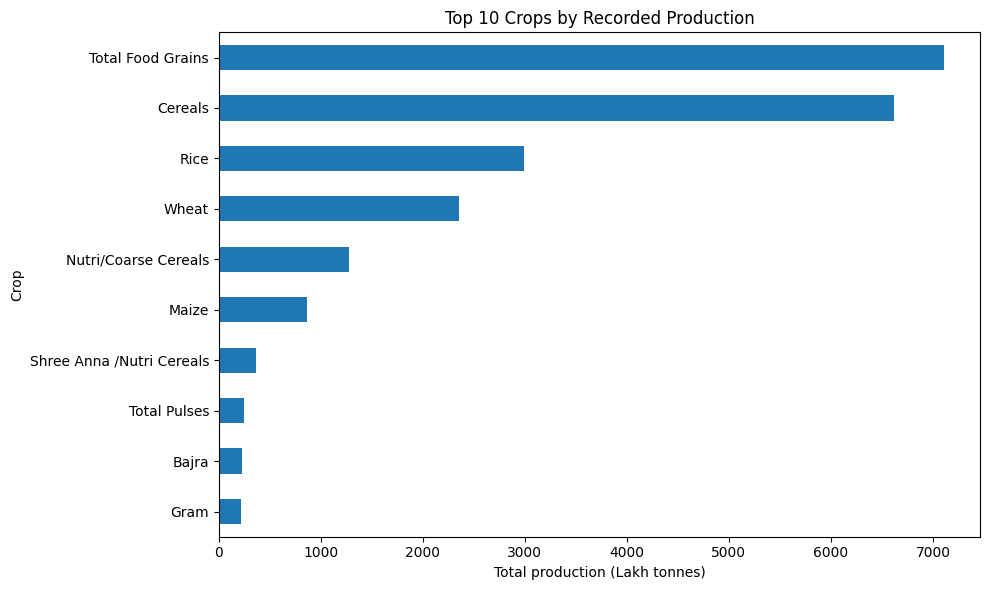

In [56]:
crop_production = (
    Df.groupby("Crop", dropna=False)["Production-2024-25"]
      .sum(min_count=1)
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 6))
crop_production.sort_values().plot(kind="barh")

plt.title("Top 10 Crops by Recorded Production")
plt.xlabel("Total production (Lakh tonnes)")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

In [57]:
# Inspect all crop categories in the dataset

print("Crop categories in the dataset:")
for crop in sorted(Df["Crop"].dropna().unique()):
    print(crop)

print("\nSeason categories:")
print(Df["Season"].value_counts(dropna=False))

Crop categories in the dataset:
Bajra
Barley
Cereals
Gram
Jowar
Lentil
Maize
Moong
Nutri/Coarse Cereals
Other Pulses
Ragi
Rice
Shree Anna /Nutri Cereals
Small Millets
Total Food Grains
Total Pulses
Tur
Urad
Wheat

Season categories:
Season
Total     10163
Kharif     7335
Rabi       5330
Summer     2411
Name: count, dtype: int64


In [58]:
# Add other aggregate categories after inspecting the crop list.

aggregate_crops = [
    "Total Food Grains",
    "Cereals",
    "Nutri/Coarse Cereals"
]

apy = Df[~Df["Crop"].isin(aggregate_crops)].copy()

print("Original records:", len(Df))
print("Records in analysis copy:", len(apy))
print("Original dataset remains unchanged.")

Original records: 25239
Records in analysis copy: 17823
Original dataset remains unchanged.


Top 10 states by recorded production:


,Production
State,
Uttar Pradesh,1333.60
Madhya Pradesh,1006.27
Rajasthan,660.60
Punjab,655.76
Maharashtra,470.19
Telangana,444.13
Bihar,431.23
Haryana,404.04
West Bengal,401.03


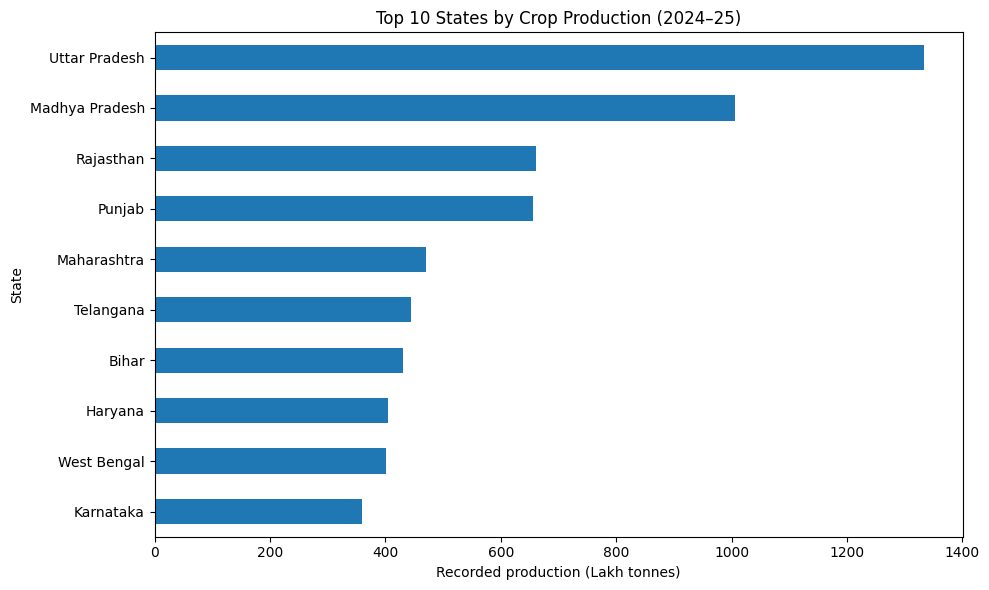

In [59]:
state_production = (
    apy.groupby("State")["Production-2024-25"]
       .sum(min_count=1)
       .sort_values(ascending=False)
)

print("Top 10 states by recorded production:")
display(state_production.head(10).to_frame("Production"))

plt.figure(figsize=(10, 6))
state_production.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 States by Crop Production (2024–25)")
plt.xlabel("Recorded production (Lakh tonnes)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

Production by season:


,Production
Season,
Total,3978.04
Kharif,1822.67
Rabi,1710.57
Summer,201.42


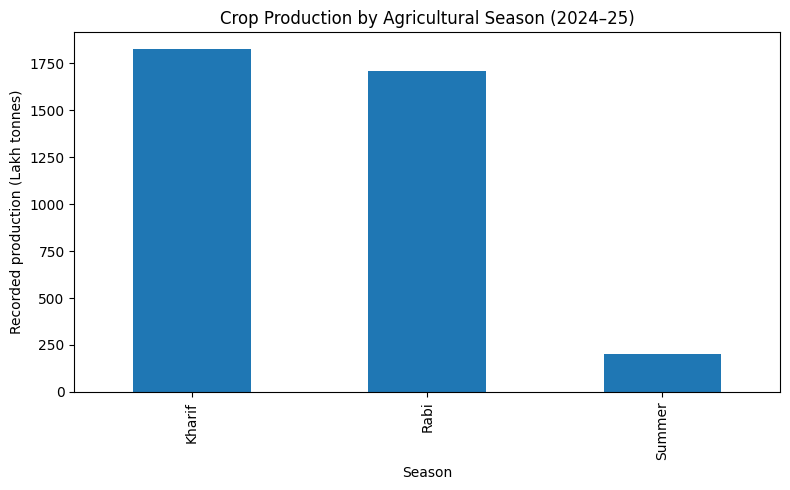

In [60]:
season_production = (
    apy.groupby("Season")["Production-2024-25"]
       .sum(min_count=1)
       .sort_values(ascending=False)
)

print("Production by season:")
display(season_production.to_frame("Production"))

season_comparison = season_production.drop(
    index="Total", errors="ignore"
)

season_comparison.plot(kind="bar", figsize=(8, 5))
plt.title("Crop Production by Agricultural Season (2024–25)")
plt.xlabel("Season")
plt.ylabel("Recorded production (Lakh tonnes)")
plt.tight_layout()
plt.show()

Area-production correlation: 0.823
Records included in this plot: 10134


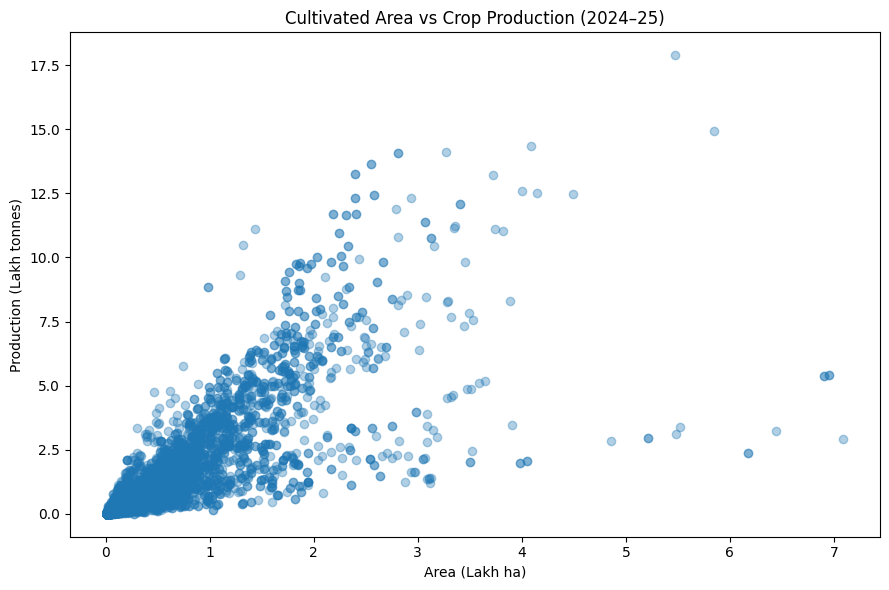

In [61]:
area_production = apy[
    apy["Area-2024-25"].notna()
    & apy["Production-2024-25"].notna()
    & (apy["Area-2024-25"] > 0)
    & (apy["Production-2024-25"] >= 0)
].copy()

correlation = area_production[
    ["Area-2024-25", "Production-2024-25"]
].corr().iloc[0, 1]

print("Area-production correlation:", round(correlation, 3))
print("Records included in this plot:", len(area_production))

plt.figure(figsize=(9, 6))
plt.scatter(
    area_production["Area-2024-25"],
    area_production["Production-2024-25"],
    alpha=0.35
)

plt.title("Cultivated Area vs Crop Production (2024–25)")
plt.xlabel("Area (Lakh ha)")
plt.ylabel("Production (Lakh tonnes)")
plt.tight_layout()
plt.show()

Yield comparison:


,count,mean,median
Crop,,,
Maize,2026,3494.746298,3177.5
Wheat,1062,2795.775895,2790.0
Rice,1792,2687.834263,2698.5
Gram,1014,1219.019724,1216.0
Tur,1040,979.788462,935.5


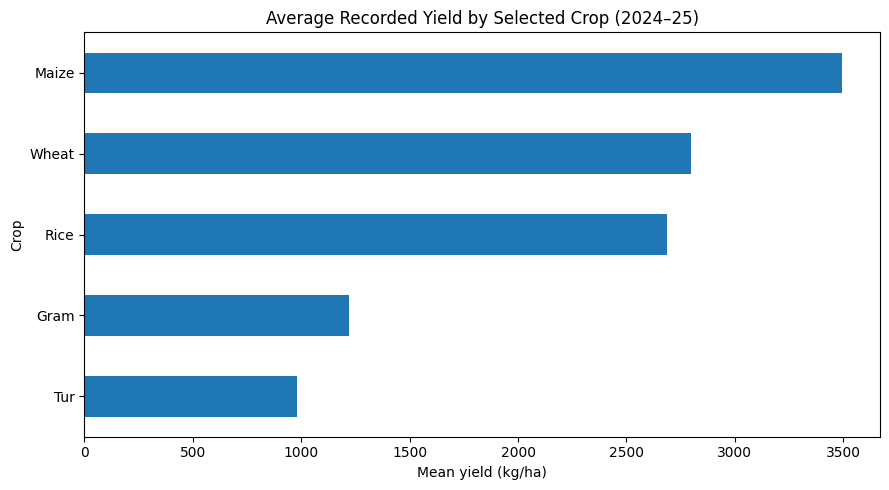

In [62]:
selected_crops = [
    "Rice",
    "Wheat",
    "Maize",
    "Gram",
    "Tur"
]

crop_yield = apy[
    apy["Crop"].isin(selected_crops)
    & apy["Yield-2024-25"].notna()
].copy()

yield_summary = (
    crop_yield.groupby("Crop")["Yield-2024-25"]
              .agg(["count", "mean", "median"])
              .sort_values("mean", ascending=False)
)

print("Yield comparison:")
display(yield_summary)

plt.figure(figsize=(9, 5))
yield_summary["mean"].sort_values().plot(kind="barh")

plt.title("Average Recorded Yield by Selected Crop (2024–25)")
plt.xlabel("Mean yield (kg/ha)")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()